In [133]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False


import pandas as pd
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression # 가장 많이 사용
from sklearn.neighbors import KNeighborsRegressor 
from sklearn.preprocessing import PolynomialFeatures # 다항특성 자동완성
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler# 정규화 클래스
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
import numpy as np
from io import StringIO

In [122]:
# 무게 데이터
perch_weight = [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]

In [123]:
df = pd.read_csv('data/perch_full.csv')
df.head(2)
df.shape


(56, 3)

In [124]:
# 학습테이터, 테스트데이터 분리
train_data,test_data,train_label,test_label = train_test_split(df,perch_weight,random_state=42)

In [125]:
# TEST
# 다항특성추가 - PolynomialFeatures
# 특성값을 추가
# length, height, width
# length**2,height**2,width**2
# poly = PolynomialFeatures(degree=2,include_bias=False)
# poly.fit([[2,3]])
# train_poly = poly.transform([[2,3]])
# train_poly


In [126]:
poly = PolynomialFeatures(degree=16,include_bias=False)
# ※ 42개 데이터에 968칸 → 외워버림(과대적합)
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)
print(train_poly.shape)
train_poly

(42, 968)


array([[1.96000000e+01, 5.14000000e+00, 3.04000000e+00, ...,
        1.52109524e+08, 8.99636098e+07, 5.32080494e+07],
       [2.20000000e+01, 5.88000000e+00, 3.52000000e+00, ...,
        1.55007225e+09, 9.27934407e+08, 5.55498148e+08],
       [1.87000000e+01, 5.20000000e+00, 3.12000000e+00, ...,
        2.23960281e+08, 1.34376169e+08, 8.06257011e+07],
       ...,
       [2.56000000e+01, 6.56000000e+00, 4.24000000e+00, ...,
        2.61173838e+10, 1.68807481e+10, 1.09107274e+10],
       [4.20000000e+01, 1.28000000e+01, 6.87000000e+00, ...,
        8.54701091e+13, 4.58734101e+13, 2.46211193e+13],
       [3.45000000e+01, 1.02600000e+01, 6.39000000e+00, ...,
        1.99207982e+13, 1.24068129e+13, 7.72705014e+12]], shape=(42, 968))

In [127]:
print(len(poly.get_feature_names_out()))

968


In [ ]:
# 규제 정규화작업 진행 - 테스트 데이터 정확도를 높이수있음.
# StandardScaler()
ss = StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)



,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

In [ ]:
# degree = 2 : 특성을 9개로 추가해서 예측
# 데이터 학습
lr = LinearRegression()
lr.fit(train_poly,train_label)
# 데이터 예측
predict = lr.predict(test_poly)




In [143]:
alpha_list = [0.001,0.01,0.1,1,10,100]
# 릿지, 라쏘 규제 2가지 형태
train_score = []
test_score = []
for a in alpha_list:
    ridge = Ridge(alpha=a)
    ridge.fit(train_scaled,train_label)

    # 정확도
    score = ridge.score(train_scaled,train_label)
    score2 = ridge.score(test_scaled,test_label)
    train_score.append(score)
    test_score.append(score2)

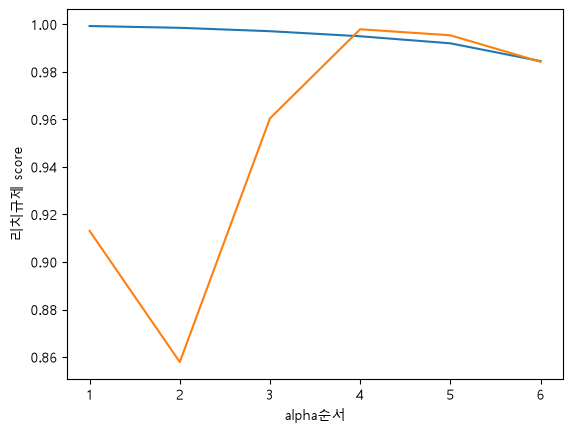

In [145]:
# 선그래프
no_list = [1,2,3,4,5,6]
plt.plot(no_list,train_score)
plt.plot(no_list,test_score)
plt.xlabel('alpha순서')
plt.ylabel('리치규제 score')
plt.show()

In [150]:
ridge = Ridge(alpha=1)
ridge.fit(train_scaled,train_label)

# 정확도
score = ridge.score(train_scaled,train_label)
score2 = ridge.score(test_scaled,test_label)
train_score.append(score)
# ※ 여기서 append하면 리스트에 7번째 값이 또 붙음 (필요 없음)
test_score.append(score2)

train_score,test_score
score,score2

(0.9949788586751355, 0.9979241216264311)

In [ ]:
# LinearRegression() : 다중회귀 - 특성값이 여러개인 것을 가지고 모델학습
# * 특성값을 더 추가 - PolynomialFeatures : 정확도를 높이기 위해 추가
# degree 추가.
# 많이 추가하면 과대적합이 생김
# 과대적합:훈련데이터는 정확도가 높은데, 테스트데이터는 현저히 정확도 떨어짐

# 그래서 규제화함
# - 정규화 작업을 해야 규제가 가능
# - Ridge 규제 : 옵션에 alpha값으로 강도 조절을함.과대적합 문제를 해결
